In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assignment Problems: Day 4
The following problems require access to the file named ‘Dataset_Day4.csv’, provided with this assignment.
About the data,
* Grades from a Chemical Engineering course at McMaster University.
* The recorded values are the average of sub-components: e.g the Tutorial variable is the average of all tutorials, the Final exam variable is the average of all questions in the final, written exam.
* The Prefix column is the year in which the student first enrolls at the university and is a crude approximation of the student's age (maturity).
* This particular course permitted students to work in groups for assignments, tutorials and the take-home exam. The groups were self-selected, and varied during the semester.
* Of interest is whether the assignments, tutorials, midterms or take-home exam are a good predictor of the student's performance in the final exam. Also, does the Prefix variable show any promise as a prediction variable?

In [2]:
data = pd.read_csv("Dataset_Day4.csv")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Prefix      99 non-null     int64  
 1   Assignment  99 non-null     float64
 2   Tutorial    99 non-null     float64
 3   Midterm     99 non-null     float64
 4   TakeHome    98 non-null     float64
 5   Final       96 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 4.8 KB


# question - 1
### Find and treat all the missing values.
### Rows or columns with missing values must not be dropped.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Prefix      99 non-null     int64  
 1   Assignment  99 non-null     float64
 2   Tutorial    99 non-null     float64
 3   Midterm     99 non-null     float64
 4   TakeHome    98 non-null     float64
 5   Final       96 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 4.8 KB


(Prefix       -1.746493
 Assignment   -1.676609
 Tutorial     -1.472330
 Midterm      -0.063458
 TakeHome     -1.175746
 Final         0.096656
 dtype: float64,
 None)

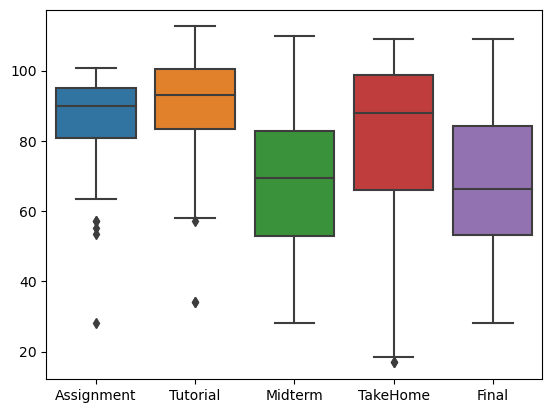

In [3]:
sns.boxplot(data = data[['Assignment', 'Tutorial', 'Midterm', 'TakeHome', 'Final']])
data.skew(),data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Prefix      99 non-null     int64  
 1   Assignment  99 non-null     float64
 2   Tutorial    99 non-null     float64
 3   Midterm     99 non-null     float64
 4   TakeHome    98 non-null     float64
 5   Final       96 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 4.8 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Prefix      99 non-null     int64  
 1   Assignment  99 non-null     float64
 2   Tutorial    99 non-null     float64
 3   Midterm     99 non-null     float64
 4   TakeHome    99 non-null     float64
 5   Final       99 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 4.8 KB


(None, None)

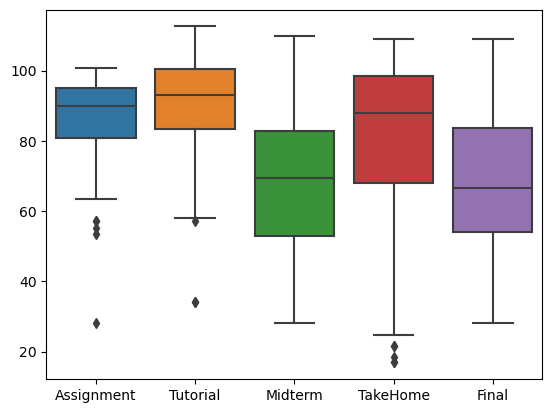

In [4]:
data_nonull = data.copy()
# TakeHome is negetively skewed hence we will use median to replace the null values
# Final is very slightly skewed ( almost zero ) hence we can use mean to replace null values
data_nonull["TakeHome"].fillna(data_nonull["TakeHome"].median(),inplace=True)
data_nonull["Final"].fillna(data_nonull["Final"].mean(),inplace=True)
sns.boxplot(data = data_nonull[['Assignment', 'Tutorial', 'Midterm', 'TakeHome', 'Final']])
data.info(),data_nonull.info()

# question - 2
### Make an in-depth report on the variables using descriptive statistics and also portray the relationship between each variables using visualizations.

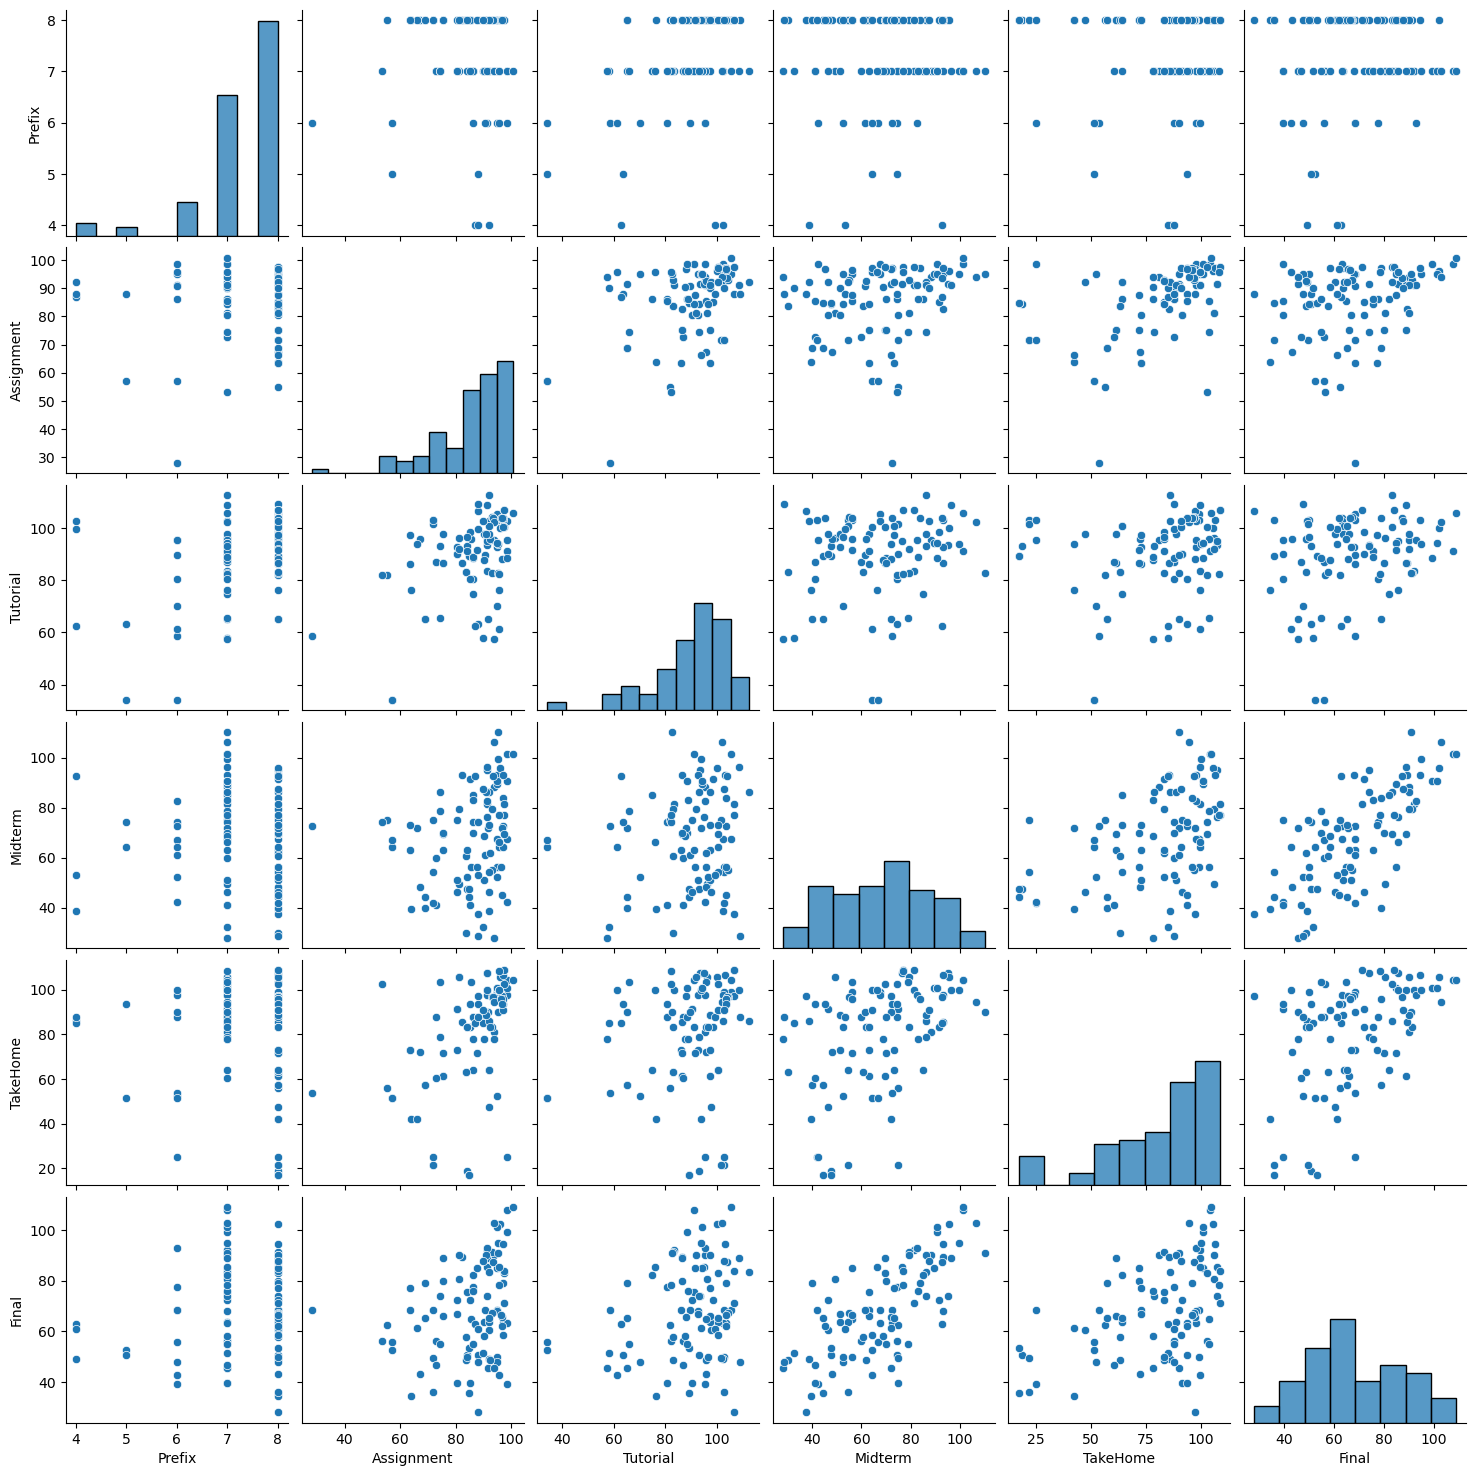

In [5]:
sns.pairplot(data_nonull)

In [6]:
data_nonull.corr()

,Prefix,Assignment,Tutorial,Midterm,TakeHome,Final
Prefix,1.000000,0.022476,0.431078,-0.062544,-0.092604,0.088832
Assignment,0.022476,1.000000,0.440115,0.215868,0.486430,0.284477
Tutorial,0.431078,0.440115,1.000000,0.135597,0.208791,0.239544
Midterm,-0.062544,0.215868,0.135597,1.000000,0.440537,0.717490
TakeHome,-0.092604,0.486430,0.208791,0.440537,1.000000,0.456543
Final,0.088832,0.284477,0.239544,0.717490,0.456543,1.000000


<Axes: >

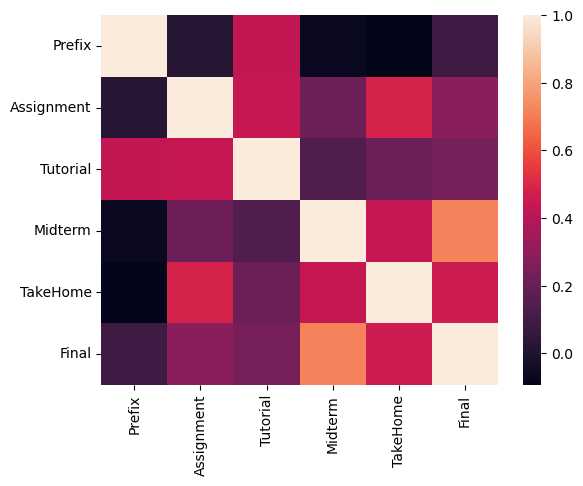

In [7]:
sns.heatmap(data_nonull.corr())

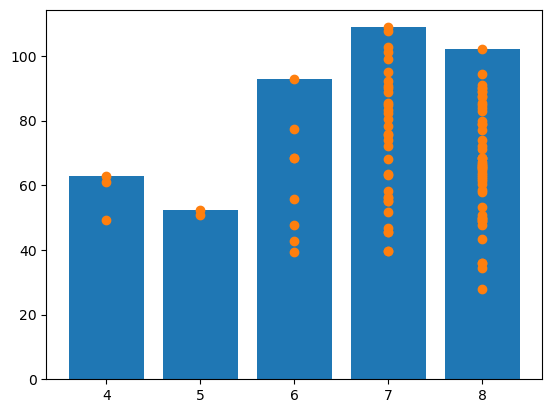

In [8]:
plt.bar(data_nonull.Prefix, data_nonull.Final)
plt.scatter(data_nonull.Prefix, data_nonull.Final)

* So we can observe from our prefix,final bar graph, scatter graph that on an average people with higher prefix have scored higher marks in Final

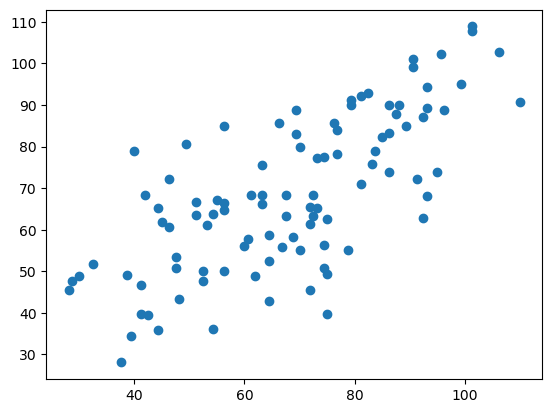

In [9]:
plt.scatter(data_nonull.Midterm, data_nonull.Final)

* In the above scatter graph, linear correlation hot , linear correlation table of Midterm and Final result seems almost linearly relatable
* We can observe this linear relation by joining a line from lower left part of the graph to the upper left part of the graph pssing through the plotted point

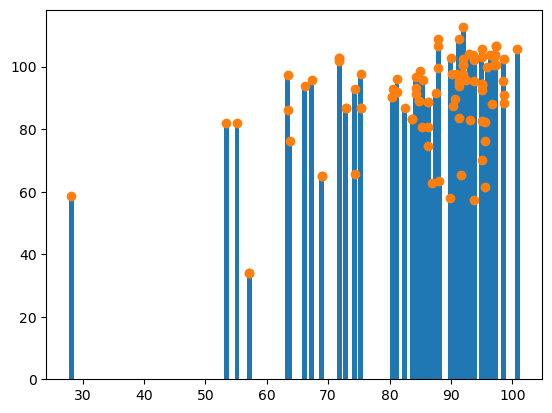

In [10]:
plt.bar(data_nonull.Assignment, data_nonull.Tutorial)
plt.scatter(data_nonull.Assignment, data_nonull.Tutorial)

* From the above graph between Assignment and Tutorial we can say that most of the people who did good in Tutorials did good in assignments too
* Most of the people did good in Assignment and Tutorial

### Name - Nikhil Khatri
### SIC     - 21BCSA92